<a href="https://colab.research.google.com/github/henryparfait/kinyarwanda-news-classifier/blob/main/notebooks/04_transformers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fine-tuning Pretrained Transformers

**Goal:** test whether Transformer models *pretrained on African languages, including Kinyarwanda* beat our best baseline (B3, char TF-IDF + balanced Logistic Regression) and our best BiLSTM (N3).

| Exp | Pretrained model | Max tokens | What changes vs. previous |
|---|---|---|---|
| T1 | AfriBERTa-base (`castorini/afriberta_base`, ~111M params, trained from scratch on 11 African languages incl. Kinyarwanda) | 256 | n/a |
| T2 | AfroXLMR-base (`Davlan/afro-xlmr-base`, ~270M params, XLM-R adapted to 17 African languages incl. Kinyarwanda) | 256 | the pretrained model |
| T3 | Better of T1/T2 (by validation score) | 512 | how much of each article the model reads |



## Step 1: Install and set up

In [ ]:
!pip install -q sentencepiece protobuf

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, json, time, math, random, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from transformers import AutoTokenizer, AutoConfig, AutoModelForSequenceClassification, DataCollatorWithPadding
import transformers
print('transformers', transformers.__version__, '| torch', torch.__version__)

PROJECT_DIR = '/content/drive/MyDrive/kinyarwanda-news-classifier'
DATA_DIR, FIG_DIR = f'{PROJECT_DIR}/data', f'{PROJECT_DIR}/figures'
RESULTS_DIR, MODEL_DIR = f'{PROJECT_DIR}/results', f'{PROJECT_DIR}/models'
LOCAL_CKPT = '/content/ckpt'
os.makedirs(LOCAL_CKPT, exist_ok=True)
LOG_PATH = f'{RESULTS_DIR}/experiment_log.csv'

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()
device = torch.device('cuda')
print('GPU:', torch.cuda.get_device_name(0))

train = pd.read_csv(f'{DATA_DIR}/train.csv')
val   = pd.read_csv(f'{DATA_DIR}/val.csv')
test  = pd.read_csv(f'{DATA_DIR}/test_dedup.csv')
test_orig = pd.read_csv(f'{DATA_DIR}/test.csv')
id2name = {int(k): v for k, v in json.load(open(f'{DATA_DIR}/label_map.json'))['id2name'].items()}
LABELS = sorted(id2name); NAMES = [id2name[i] for i in LABELS]
print(f'train {len(train)} | val {len(val)} | test {len(test)}')

Mounted at /content/drive
transformers 5.18.0 | torch 2.11.0+cu130
GPU: Tesla T4
train 6726 | val 745 | test 3464


## Step 2: Evaluation helpers and class weights
Class weights use the same formula as B3 (`balanced`): weight = N / (K × count of that class). Rare classes like *tourism* get large weights, and common ones like *politic* get small weights.

In [ ]:
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

def compute_metrics(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=LABELS, average='macro', zero_division=0)
    return {'accuracy': accuracy_score(y_true, y_pred), 'macro_precision': p, 'macro_recall': r,
            'macro_f1': f, 'weighted_f1': f1_score(y_true, y_pred, labels=LABELS, average='weighted', zero_division=0)}

def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, labels=LABELS, average='macro', zero_division=0)

def log_experiment(row):
    log = pd.read_csv(LOG_PATH)
    log = log[log['exp_id'] != row['exp_id']]
    new = pd.DataFrame([row])
    log = new if log.empty else pd.concat([log, new], ignore_index=True)
    log.to_csv(LOG_PATH, index=False)

counts = train['label_id'].value_counts().reindex(LABELS).values
class_weights = torch.tensor(len(train) / (len(LABELS) * counts), dtype=torch.float)
print(pd.DataFrame({'class': NAMES, 'train_count': counts, 'weight': class_weights.numpy().round(2)}).to_string(index=False))

        class  train_count  weight
      politic         1591    0.30
        sport          878    0.55
      economy          998    0.48
       health          976    0.49
entertainment          900    0.53
      history          196    2.45
   technology          135    3.56
      tourism           30   16.01
      culture           69    6.96
      fashion           34   14.13
     religion          401    1.20
  environment           34   14.13
    education          104    4.62
 relationship          380    1.26


## Step 3: How do the tokenizers handle Kinyarwanda?
Transformers split words into **sub-word pieces**. *Fertility* (pieces per word) shows how well a tokenizer fits a language. Lower is better, because each piece is more meaningful and more of the article fits in the token limit. We also measure how many articles get truncated at 256 and 512 tokens.

In [ ]:
MODELS = {'AfriBERTa-base': 'castorini/afriberta_base', 'AfroXLMR-base': 'Davlan/afro-xlmr-base'}

def load_tokenizer(name):
    try:
        tok = AutoTokenizer.from_pretrained(name)
    except Exception as e:
        print('Fast tokenizer failed, falling back to slow one:', type(e).__name__)
        tok = AutoTokenizer.from_pretrained(name, use_fast=False)
    tok.model_max_length = 512
    return tok

sample = train['text'].sample(300, random_state=SEED).tolist()
example = 'Abanyeshuri bo mu Rwanda bakoze ikizamini cya Leta neza cyane.'
rows = []
for short, name in MODELS.items():
    tok = load_tokenizer(name)
    n_tok = np.array([len(tok(t, add_special_tokens=False)['input_ids']) for t in sample])
    n_w = np.array([len(t.split()) for t in sample])
    rows.append({'model': short, 'vocab_size': tok.vocab_size,
                 'fertility (tokens/word)': round(n_tok.sum() / n_w.sum(), 2),
                 'median tokens/article': int(np.median(n_tok)),
                 '% truncated at 256': f'{(n_tok > 254).mean():.0%}',
                 '% truncated at 512': f'{(n_tok > 510).mean():.0%}'})
    print(f'{short:15s}:', tok.tokenize(example))
tok_df = pd.DataFrame(rows); tok_df.to_csv(f'{RESULTS_DIR}/tokenizer_stats.csv', index=False)
tok_df

config.json:   0%|          | 0.00/729 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/257 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 1.55MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/9.08M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (687 > 512). Running this sequence through the model will result in indexing errors


AfroXLMR-base  : ['▁Aba', 'ny', 'es', 'huri', '▁bo', '▁mu', '▁Rwanda', '▁bak', 'oze', '▁iki', 'za', 'mini', '▁c', 'ya', '▁Leta', '▁neza', '▁cy', 'ane', '.']


,model,vocab_size,fertility (tokens/word),median tokens/article,% truncated at 256,% truncated at 512
0,AfriBERTa-base,70006,1.88,525,95%,54%
1,AfroXLMR-base,250002,2.49,713,96%,77%


## Step 4: Data loading
Texts are tokenised once, then padded **per batch** (dynamic padding) so short batches don't waste computation.

In [ ]:
class TextDataset(Dataset):
    def __init__(self, enc, labels):
        self.enc, self.labels = enc, labels
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        return {'input_ids': self.enc['input_ids'][i], 'attention_mask': self.enc['attention_mask'][i],
                'labels': int(self.labels[i])}

def make_loader(tok, df, max_len, bs, shuffle):
    enc = tok(df['text'].tolist(), truncation=True, max_length=max_len)
    return DataLoader(TextDataset(enc, df['label_id'].values), batch_size=bs, shuffle=shuffle,
                      collate_fn=DataCollatorWithPadding(tok),
                      generator=torch.Generator().manual_seed(SEED) if shuffle else None)

@torch.no_grad()
def predict(model, loader):
    model.eval(); probs = []
    for b in loader:
        b = {k: v.to(device) for k, v in b.items() if k != 'labels'}
        with torch.autocast('cuda', dtype=torch.float16):
            logits = model(**b).logits
        probs.append(torch.softmax(logits.float(), dim=-1).cpu())
    P = torch.cat(probs).numpy()
    return P.argmax(1), P

## Step 5: The fine-tuning loop
- Pretrained encoder + a new linear classification head on the `<s>` (first-token) representation.
- **AdamW**, learning rate 3e-5, weight decay 0.01, **linear warm-up (10%) then linear decay**. Warm-up avoids large early updates that would damage the pretrained weights.
- **Mixed precision (fp16)** for speed and memory, and gradient clipping at 1.0.
- **Weighted cross-entropy** (Step 2).
- Validation macro-F1 after each epoch, keeping the best epoch and stopping after 2 epochs without improvement.

In [ ]:
def run_transformer(exp_id, short_name, max_len=256, lr=3e-5, epochs=6, bs=16, grad_accum=1, patience=2, notes=''):
    set_seed()
    name = MODELS[short_name]
    max_len = min(max_len, AutoConfig.from_pretrained(name).max_position_embeddings - 2)
    tok = load_tokenizer(name)
    tr_dl = make_loader(tok, train, max_len, bs, True)
    va_dl = make_loader(tok, val, max_len, 64, False)
    model = AutoModelForSequenceClassification.from_pretrained(
        name, num_labels=len(LABELS), id2label=id2name, label2id={v: k for k, v in id2name.items()}).to(device)

    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    total = math.ceil(len(tr_dl) / grad_accum) * epochs
    warm = max(1, int(0.1 * total))
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: min((s + 1) / warm, max(0.0, (total - s) / max(1, total - warm))))
    crit = nn.CrossEntropyLoss(weight=class_weights.to(device))
    scaler = torch.amp.GradScaler('cuda')

    best_f1, bad, hist, t0 = -1.0, 0, [], time.time()
    ckpt = f'{LOCAL_CKPT}/{exp_id}'
    for ep in range(1, epochs + 1):
        model.train(); run_loss = 0.0; opt.zero_grad()
        for step, b in enumerate(tr_dl):
            labels = b.pop('labels').to(device)
            b = {k: v.to(device) for k, v in b.items()}
            with torch.autocast('cuda', dtype=torch.float16):
                logits = model(**b).logits
            loss = crit(logits.float(), labels) / grad_accum
            scaler.scale(loss).backward()
            run_loss += loss.item() * grad_accum * len(labels)
            if (step + 1) % grad_accum == 0 or step + 1 == len(tr_dl):
                scaler.unscale_(opt)
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt); scaler.update(); opt.zero_grad(); sched.step()
        vp, _ = predict(model, va_dl)
        vf = macro_f1(val['label_id'].values, vp)
        hist.append({'epoch': ep, 'train_loss': run_loss / len(train), 'val_macro_f1': vf})
        print(f'  epoch {ep} | train loss {run_loss/len(train):.4f} | val macro-F1 {vf:.4f} | {(time.time()-t0)/60:.1f} min')
        if vf > best_f1:
            best_f1, bad = vf, 0
            model.save_pretrained(ckpt); tok.save_pretrained(ckpt)
        else:
            bad += 1
            if bad >= patience:
                print('  early stopping'); break
    minutes = (time.time() - t0) / 60

    # reload best epoch and evaluate once on test
    del model; torch.cuda.empty_cache()
    model = AutoModelForSequenceClassification.from_pretrained(ckpt).to(device)
    te_pred, te_prob = predict(model, make_loader(tok, test, max_len, 64, False))
    or_pred, _ = predict(model, make_loader(tok, test_orig, max_len, 64, False))
    m, m_orig = compute_metrics(test['label_id'].values, te_pred), compute_metrics(test_orig['label_id'].values, or_pred)
    config = f'{name}, max_len={max_len}, lr={lr}, bs={bs*grad_accum}, weighted CE, best epoch={int(np.argmax([h["val_macro_f1"] for h in hist]))+1}'
    log_experiment({'exp_id': exp_id, 'model': f'{short_name} fine-tuned', 'config': config,
                    'val_macro_f1': round(best_f1, 4), 'test_accuracy': round(m['accuracy'], 4),
                    'test_macro_f1': round(m['macro_f1'], 4), 'test_weighted_f1': round(m['weighted_f1'], 4),
                    'orig_test_macro_f1': round(m_orig['macro_f1'], 4), 'train_time_min': round(minutes, 2), 'notes': notes})
    print(f'{exp_id}: val F1 {best_f1:.4f} | TEST acc {m["accuracy"]:.4f} macro-F1 {m["macro_f1"]:.4f} '
          f'weighted-F1 {m["weighted_f1"]:.4f} | {minutes:.1f} min')

    h = pd.DataFrame(hist); h.to_csv(f'{RESULTS_DIR}/{exp_id}_history.csv', index=False)
    fig, ax1 = plt.subplots(figsize=(7, 3.5)); ax2 = ax1.twinx()
    ax1.plot(h.epoch, h.train_loss, 'o-'); ax1.set_xlabel('epoch'); ax1.set_ylabel('train loss')
    ax2.plot(h.epoch, h.val_macro_f1, 's-', color='tab:orange'); ax2.set_ylabel('val macro-F1')
    plt.title(f'{exp_id} ({short_name}, max_len={max_len})'); plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/{exp_id}_training_curve.png', dpi=200); plt.show()

    del model; torch.cuda.empty_cache()
    return {'exp_id': exp_id, 'short': short_name, 'max_len': max_len, 'val_f1': best_f1,
            'pred': te_pred, 'prob': te_prob, 'ckpt': ckpt}

## Step 6: T1, AfriBERTa-base (≈10–15 min)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  446MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/133 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: castorini/afriberta_base
Key                        | Status     | 
---------------------------+------------+-
lm_head.decoder.bias       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.decoder.weight     | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


model.safetensors: reconstructing file:   0%|          |  0.00B /  446MB            

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  epoch 5 | train loss 0.2698 | val macro-F1 0.6779 | 5.8 min
  epoch 6 | train loss 0.1672 | val macro-F1 0.6863 | 6.9 min


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/137 [00:00<?, ?it/s]

T1: val F1 0.6863 | TEST acc 0.7483 macro-F1 0.5779 weighted-F1 0.7422 | 7.0 min


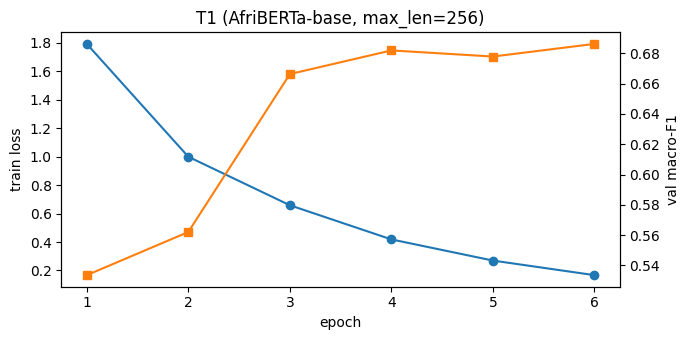

In [ ]:
r1 = run_transformer('T1', 'AfriBERTa-base', max_len=256, notes='African-centric model pretrained from scratch')

## Step 7: T2, AfroXLMR-base (≈15–20 min). One change: the pretrained model

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch 1 | train loss 1.8881 | val macro-F1 0.5377 | 2.2 min


...

  epoch 4 | train loss 0.5059 | val macro-F1 0.6646 | 10.2 min


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  epoch 5 | train loss 0.3291 | val macro-F1 0.6311 | 12.9 min
  epoch 6 | train loss 0.2479 | val macro-F1 0.6616 | 15.0 min
  early stopping


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

T2: val F1 0.6646 | TEST acc 0.7731 macro-F1 0.6176 weighted-F1 0.7705 | 15.0 min


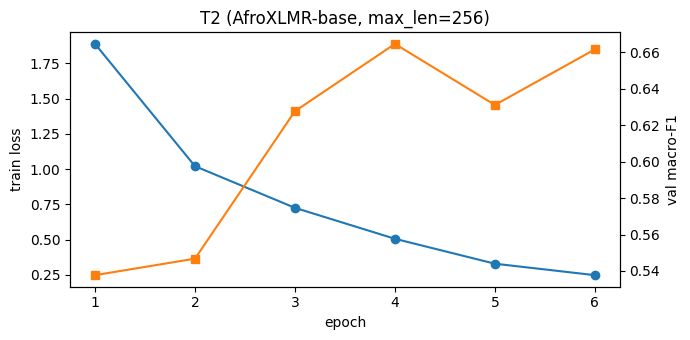

In [ ]:
r2 = run_transformer('T2', 'AfroXLMR-base', max_len=256, notes='XLM-R adapted to African languages (MAFT)')

## Step 8: T3, the better model with 512 tokens (≈20–30 min). One change: context length
Batch of 8 with 2 gradient-accumulation steps keeps the effective batch at 16 while fitting longer inputs in GPU memory.

Re-running AfriBERTa-base with 512 tokens (chosen by validation macro-F1)


Loading weights:   0%|          | 0/133 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: castorini/afriberta_base
Key                        | Status     | 
---------------------------+------------+-
lm_head.decoder.bias       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.decoder.weight     | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch 1 | train loss 1.6948 | val macro-F1 0.5382 | 2.1 min


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

  epoch 4 | train loss 0.3941 | val macro-F1 0.6909 | 9.1 min


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  epoch 5 | train loss 0.2575 | val macro-F1 0.6792 | 11.3 min
  epoch 6 | train loss 0.1682 | val macro-F1 0.6755 | 13.5 min
  early stopping


Loading weights:   0%|          | 0/137 [00:00<?, ?it/s]

T3: val F1 0.6909 | TEST acc 0.7546 macro-F1 0.5810 weighted-F1 0.7509 | 13.5 min


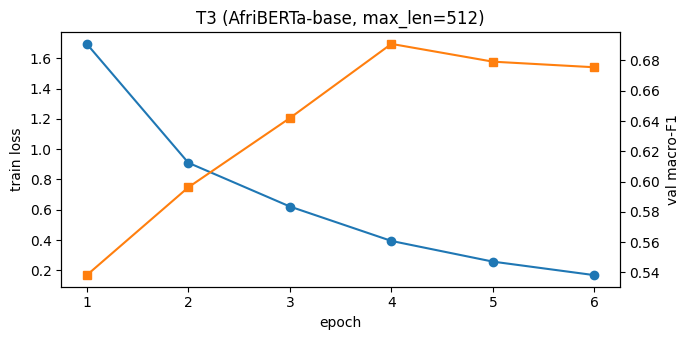

In [ ]:
best_short = r1['short'] if r1['val_f1'] >= r2['val_f1'] else r2['short']
print('Re-running', best_short, 'with 512 tokens (chosen by validation macro-F1)')
r3 = run_transformer('T3', best_short, max_len=512, bs=8, grad_accum=2, notes='longer context (512 tokens)')

## Step 9: Save the best Transformer (for deployment and error analysis)
Chosen by **validation** macro-F1.

Best Transformer: T3 AfriBERTa-base max_len 512
               precision    recall  f1-score   support

      politic      0.664     0.648     0.656       315
        sport      0.949     0.957     0.953       744
      economy      0.512     0.730     0.602       174
       health      0.648     0.691     0.669       272
entertainment      0.873     0.826     0.849       774
      history      0.088     0.818     0.159        11
   technology      0.560     0.767     0.648       103
      tourism      0.776     0.500     0.608        76
      culture      0.550     0.319     0.404       138
      fashion      0.662     0.538     0.594        91
     religion      0.732     0.801     0.765       256
  environment      0.833     0.200     0.323       100
    education      0.176     0.043     0.069        70
 relationship      0.803     0.874     0.837       340

     accuracy                          0.755      3464
    macro avg      0.631     0.622     0.581      3464
 weighted avg  

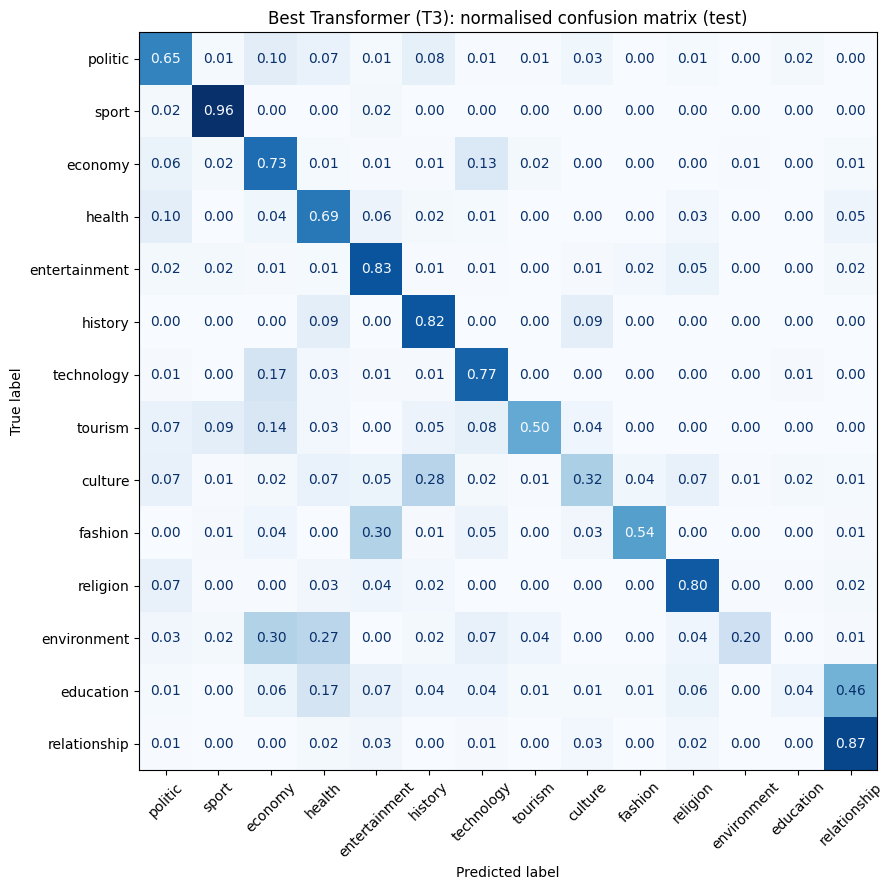

In [ ]:
runs = {r['exp_id']: r for r in [r1, r2, r3]}
best = max(runs.values(), key=lambda r: r['val_f1'])
print('Best Transformer:', best['exp_id'], best['short'], 'max_len', best['max_len'])

dest = f'{MODEL_DIR}/best_transformer'
if os.path.exists(dest): shutil.rmtree(dest)
shutil.copytree(best['ckpt'], dest)
json.dump({'exp_id': best['exp_id'], 'model': MODELS[best['short']], 'max_len': best['max_len']},
          open(f'{dest}/run_info.json', 'w'), indent=2)

y = test['label_id'].values
pd.DataFrame({'text': test['text'], 'true': pd.Series(y).map(id2name),
              'pred': pd.Series(best['pred']).map(id2name),
              'confidence': best['prob'].max(1).round(4)}).to_csv(
    f'{RESULTS_DIR}/best_transformer_test_predictions.csv', index=False)

print(classification_report(y, best['pred'], labels=LABELS, target_names=NAMES, digits=3, zero_division=0))
pd.DataFrame(classification_report(y, best['pred'], labels=LABELS, target_names=NAMES,
             zero_division=0, output_dict=True)).T.round(4).to_csv(
    f'{RESULTS_DIR}/{best["exp_id"]}_classification_report.csv')

cm = confusion_matrix(y, best['pred'], labels=LABELS, normalize='true')
fig, ax = plt.subplots(figsize=(10, 9))
ConfusionMatrixDisplay(cm, display_labels=NAMES).plot(ax=ax, cmap='Blues', values_format='.2f',
                                                      colorbar=False, xticks_rotation=45)
ax.set_title(f'Best Transformer ({best["exp_id"]}): normalised confusion matrix (test)')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/{best["exp_id"]}_confusion_matrix.png', dpi=200); plt.show()

## Step 10: Full experiment table

In [ ]:
log = pd.read_csv(LOG_PATH)
log = log.drop_duplicates('exp_id', keep='last').sort_values('exp_id', key=lambda s: s.str[0].map({'B': 0, 'N': 1, 'T': 2}) * 10 + s.str[1:].astype(int))
log.to_csv(LOG_PATH, index=False)
log[['exp_id', 'model', 'val_macro_f1', 'test_accuracy', 'test_macro_f1', 'test_weighted_f1', 'train_time_min']]

,exp_id,model,val_macro_f1,test_accuracy,test_macro_f1,test_weighted_f1,train_time_min
0,B0,Majority class,0.0273,0.0909,0.0119,0.0152,0.00
1,B1,Word TF-IDF + LogReg,0.5528,0.6911,0.4133,0.6555,3.71
2,B2,Char TF-IDF + LogReg,0.6231,0.7099,0.4584,0.6812,7.50
3,B3,Char TF-IDF + LogReg (balanced),0.7451,0.7428,0.5773,0.7421,5.23
4,N1,"BiLSTM (random emb, max pool)",0.5303,0.5756,0.3538,0.5723,2.12
5,N2,"BiLSTM (Word2Vec emb, max pool)",0.5436,0.5950,0.3828,0.5938,1.37
6,N3,"BiLSTM (Word2Vec emb, attention pool)",0.6308,0.6848,0.5132,0.6871,1.65
7,T1,AfriBERTa-base fine-tuned,0.6863,0.7483,0.5779,0.7422,7.01
8,T2,AfroXLMR-base fine-tuned,0.6646,0.7731,0.6176,0.7705,14.97
9,T3,AfriBERTa-base fine-tuned,0.6909,0.7546,0.5810,0.7509,13.51
